In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/omaryan77/titanic-dataset/train.csv
/kaggle/input/datasets/omaryan77/titanic-dataset/test.csv
/kaggle/input/datasets/omaryan77/titanic-dataset/gender_submission.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [3]:
train = pd.read_csv(r"/kaggle/input/datasets/omaryan77/titanic-dataset/train.csv")
test = pd.read_csv(r"/kaggle/input/datasets/omaryan77/titanic-dataset/test.csv")
gender_submission=pd.read_csv(r"/kaggle/input/datasets/omaryan77/titanic-dataset/gender_submission.csv")
print(train.shape, test.shape)
train.head()

(891, 12) (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


# EDA 

**Inspecting data**

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [6]:
train.duplicated().sum()

np.int64(0)

In [7]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

# Visualisation -Univariate analysis**

**numeric columns**

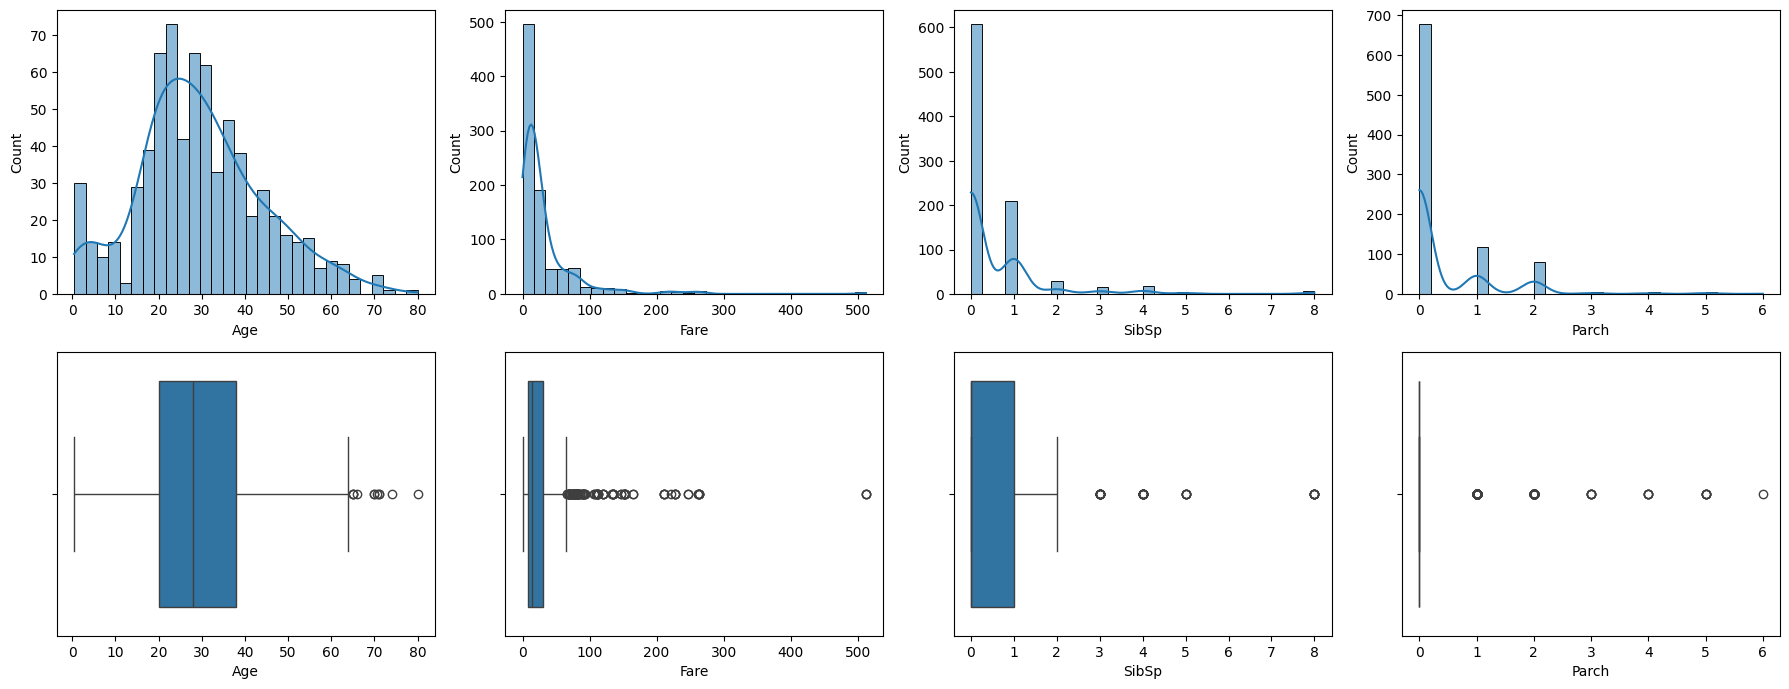

Age     0.389108
Fare    4.787317
dtype: float64


In [8]:
num_cols = ["Age", "Fare", "SibSp", "Parch"]
fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_cols):
    sns.histplot(train[c].dropna(), bins=30, kde=True, ax=ax[0, i])
    sns.boxplot(x=train[c], ax=ax[1, i])
plt.tight_layout(); plt.show()
print(train[["Age", "Fare"]].skew())

**categorical columns**

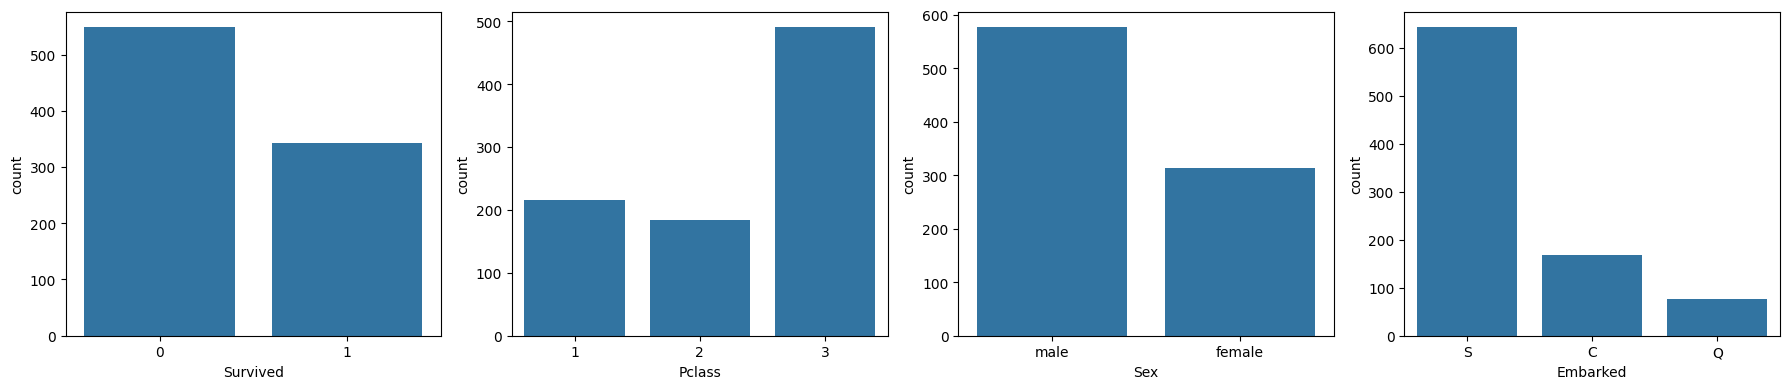

In [9]:
cat_cols = ["Survived", "Pclass", "Sex", "Embarked"]
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for i, c in enumerate(cat_cols):
    sns.countplot(x=c, data=train, ax=ax[i])
plt.tight_layout(); plt.show()

# Bivariate (each feature vs Survived)

**Categorical vs survival rate**

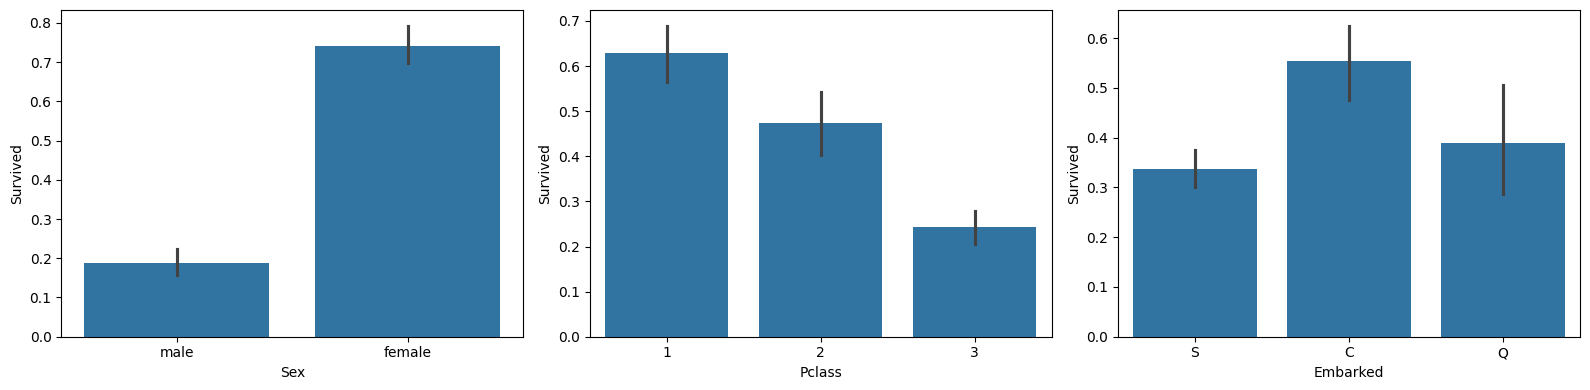

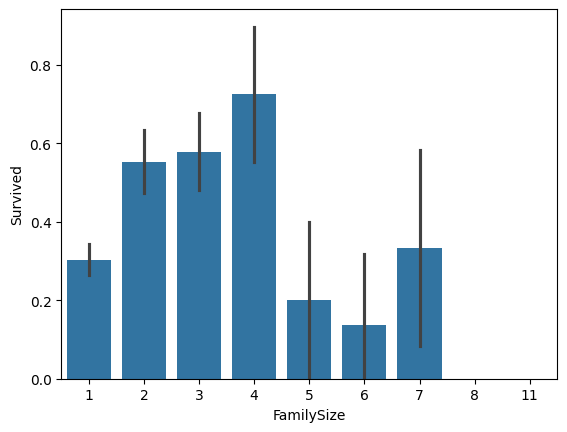

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, c in enumerate(["Sex", "Pclass", "Embarked"]):
    sns.barplot(x=c, y="Survived", data=train, ax=ax[i])
plt.tight_layout(); plt.show()

train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
sns.barplot(x="FamilySize", y="Survived", data=train); plt.show()

**Numeric vs survival**

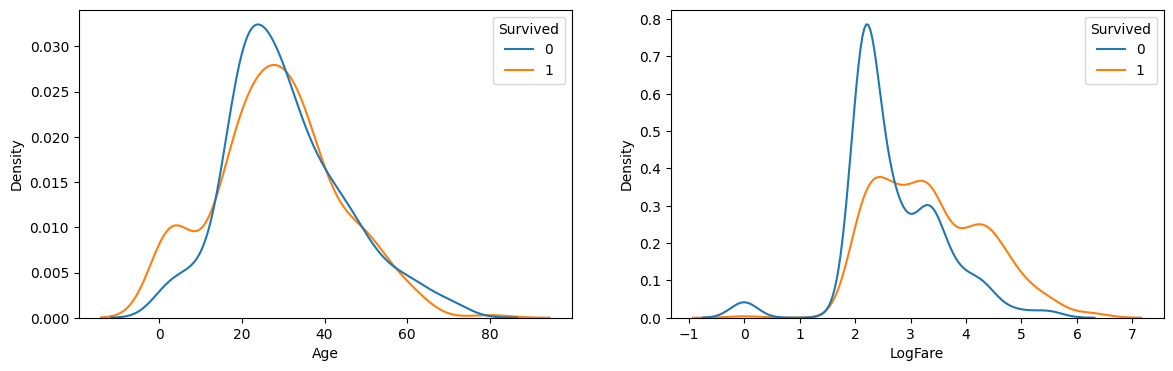

In [11]:
train["LogFare"] = np.log1p(train["Fare"])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(data=train, x="Age", hue="Survived", common_norm=False, ax=ax[0])
sns.kdeplot(data=train, x="LogFare", hue="Survived", common_norm=False, ax=ax[1])
plt.show()

**Missingness as a signal**

In [12]:
train["CabinKnown"] = train["Cabin"].notna().astype(int)
train["AgeMissing"] = train["Age"].isna().astype(int)
print(train.groupby("CabinKnown")["Survived"].mean())
print(train.groupby("AgeMissing")["Survived"].mean())

CabinKnown
0    0.299854
1    0.666667
Name: Survived, dtype: float64
AgeMissing
0    0.406162
1    0.293785
Name: Survived, dtype: float64


**Family and ticket groups**

In [17]:
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
train["TicketGroupSize"] = train.groupby("Ticket")["Ticket"].transform("count")

print(train.groupby("TicketGroupSize")["Survived"].agg(["mean", "count"]))
print(pd.crosstab(train["FamilySize"], train["TicketGroupSize"]))

                     mean  count
TicketGroupSize                 
1                0.297989    547
2                0.574468    188
3                0.698413     63
4                0.500000     44
5                0.000000     10
6                0.000000     18
7                0.238095     21
TicketGroupSize    1   2   3   4  5   6  7
FamilySize                                
1                462  40  17   9  2   0  7
2                 58  87  15   1  0   0  0
3                 24  48  24   3  3   0  0
4                  1  11   6  11  0   0  0
5                  1   2   0  12  0   0  0
6                  0   0   1   4  5  12  0
7                  1   0   0   4  0   0  7
8                  0   0   0   0  0   6  0
11                 0   0   0   0  0   0  7


**Outlier and small-group checks**

In [18]:
print(train[train["Fare"] > 200][["Pclass", "Sex", "Survived", "Ticket"]].describe(include="all"))
print(train[train["FamilySize"] >= 5].groupby("Pclass")["Survived"].agg(["mean", "count"]))
print(train[(train["Age"] > 60) & (train["Sex"] == "female")][["Pclass", "Age", "Survived"]])

        Pclass     Sex   Survived Ticket
count     20.0      20  20.000000     20
unique     NaN       2        NaN      8
top        NaN  female        NaN  19950
freq       NaN      12        NaN      4
mean       1.0     NaN   0.700000    NaN
std        0.0     NaN   0.470162    NaN
min        1.0     NaN   0.000000    NaN
25%        1.0     NaN   0.000000    NaN
50%        1.0     NaN   1.000000    NaN
75%        1.0     NaN   1.000000    NaN
max        1.0     NaN   1.000000    NaN
            mean  count
Pclass                 
1       0.666667      6
2       1.000000      2
3       0.074074     54
     Pclass   Age  Survived
275       1  63.0         1
483       3  63.0         1
829       1  62.0         1


# Multivariate (interactions)

**Sex × Pclass, and Age groups**

In [13]:
print(train.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc=["mean", "count"]))

train["AgeBin"] = pd.cut(train["Age"], [0, 12, 18, 35, 60, 80])
print(train.pivot_table(values="Survived", index="AgeBin", columns="Sex", aggfunc="mean", observed=True))

            mean                     count          
Pclass         1         2         3     1    2    3
Sex                                                 
female  0.968085  0.921053  0.500000    94   76  144
male    0.368852  0.157407  0.135447   122  108  347
Sex         female      male
AgeBin                      
(0, 12]   0.593750  0.567568
(12, 18]  0.750000  0.088235
(18, 35]  0.783333  0.180672
(35, 60]  0.771429  0.192000
(60, 80]  1.000000  0.105263


**Correlation heatmap**

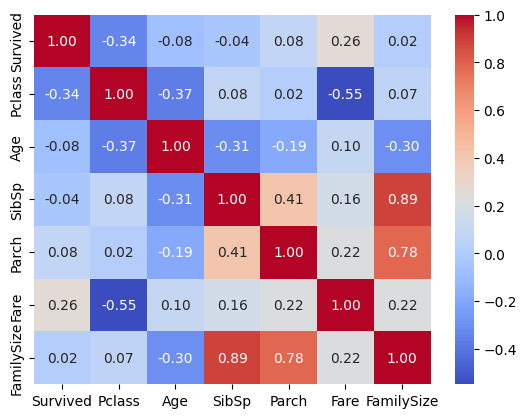

In [14]:
sns.heatmap(train[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f"); plt.show()

**Titles hidden in names (feature idea)**

In [15]:
train["Title"] = train["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
print(train["Title"].value_counts())
print(train.groupby("Title")["Survived"].agg(["mean", "count"]))
train.groupby("Title")["Age"].median()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64
                  mean  count
Title                        
Capt          0.000000      1
Col           0.500000      2
Don           0.000000      1
Dr            0.428571      7
Jonkheer      0.000000      1
Lady          1.000000      1
Major         0.500000      2
Master        0.575000     40
Miss          0.697802    182
Mlle          1.000000      2
Mme           1.000000      1
Mr            0.156673    517
Mrs           0.792000    125
Ms            1.000000      1
Rev           0.000000      6
Sir           1.000000      1
the Countess  1.000000      1


Title
Capt            70.0
Col             58.0
Don             40.0
Dr              46.5
Jonkheer        38.0
Lady            48.0
Major           48.5
Master           3.5
Miss            21.0
Mlle            24.0
Mme             24.0
Mr              30.0
Mrs             35.0
Ms              28.0
Rev             46.5
Sir             49.0
the Countess    33.0
Name: Age, dtype: float64

**Embarked × Pclass × Sex**

In [16]:
print(pd.crosstab(train["Embarked"], train["Pclass"], normalize="index").round(2))
print(train.pivot_table(values="Survived", index=["Pclass", "Sex"],
                        columns="Embarked", aggfunc=["mean", "count"]))

Pclass       1     2     3
Embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0.25  0.55
                   mean                     count         
Embarked              C         Q         S     C   Q    S
Pclass Sex                                                
1      female  0.976744  1.000000  0.958333    43   1   48
       male    0.404762  0.000000  0.354430    42   1   79
2      female  1.000000  1.000000  0.910448     7   2   67
       male    0.200000  0.000000  0.154639    10   1   97
3      female  0.652174  0.727273  0.375000    23  33   88
       male    0.232558  0.076923  0.128302    43  39  265


# Data pre-processing

**Reload raw data and combine**

In [19]:
train_raw = pd.read_csv(r"/kaggle/input/datasets/omaryan77/titanic-dataset/train.csv")
test_raw  = pd.read_csv(r"/kaggle/input/datasets/omaryan77/titanic-dataset/test.csv")

y = train_raw["Survived"].copy()
train_raw["is_train"] = True
test_raw["is_train"] = False

full = pd.concat([train_raw.drop(columns="Survived"), test_raw], ignore_index=True)
train_mask = full["is_train"]
print(full.shape, train_mask.sum())

(1309, 12) 891


**Title (extract and group)**

In [20]:
full["Title"] = full["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()

title_map = {"Mr": "Mr", "Miss": "Miss", "Mrs": "Mrs", "Master": "Master",
             "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs", "Lady": "Mrs",
             "the Countess": "Mrs", "Dona": "Mrs"}
full["Title"] = full["Title"].map(title_map).fillna("Rare")   # Dr, Rev, Col, Major, Capt, Sir, Don, Jonkheer
print(full["Title"].value_counts())

Title
Mr        757
Miss      264
Mrs       201
Master     61
Rare       26
Name: count, dtype: int64


**Missing-value flags**

In [21]:
full["AgeMissing"]  = full["Age"].isna().astype(int)
full["CabinKnown"]  = full["Cabin"].notna().astype(int)

**Fill missing values (learned from train only)**

In [22]:
# Age: median by (Title, Pclass), fallback to Title, then global
tp_med = full[train_mask].groupby(["Title", "Pclass"])["Age"].median()
t_med  = full[train_mask].groupby("Title")["Age"].median()
g_med  = full.loc[train_mask, "Age"].median()

idx = pd.MultiIndex.from_frame(full[["Title", "Pclass"]])
age_fill = pd.Series(tp_med.reindex(idx).values, index=full.index)
age_fill = age_fill.fillna(full["Title"].map(t_med)).fillna(g_med)
full["Age"] = full["Age"].fillna(age_fill)

# Fare: median by Pclass (only 1 missing, in test)
fare_med = full[train_mask].groupby("Pclass")["Fare"].median()
full["Fare"] = full["Fare"].fillna(full["Pclass"].map(fare_med))

# Embarked: mode of train (2 missing)
full["Embarked"] = full["Embarked"].fillna(full.loc[train_mask, "Embarked"].mode()[0])

print(full[["Age", "Fare", "Embarked"]].isna().sum())

Age         0
Fare        0
Embarked    0
dtype: int64


# Feature engineering

In [23]:
full["FamilySize"] = full["SibSp"] + full["Parch"] + 1
full["FamilyGroup"] = pd.cut(full["FamilySize"], [0, 1, 4, 20], labels=["Alone", "Small", "Large"])

# Label-free, so counting on train+test combined is fine
full["TicketGroupSize"] = full.groupby("Ticket")["Ticket"].transform("count")
full["TicketGroup"] = pd.cut(full["TicketGroupSize"], [0, 1, 4, 20], labels=["Alone", "Small", "Large"])

full["LogFare"] = np.log1p(full["Fare"])
full["FarePerPerson"] = full["Fare"] / full["TicketGroupSize"]
full["Sex"] = full["Sex"].map({"male": 0, "female": 1})

In [24]:
num_feats = ["Pclass", "Sex", "Age", "LogFare", "FarePerPerson", "FamilySize",
             "TicketGroupSize", "AgeMissing", "CabinKnown"]
cat_feats = ["Title", "Embarked", "FamilyGroup", "TicketGroup"]

data = pd.concat([full[num_feats],
                  pd.get_dummies(full[cat_feats].astype(str), dtype=int)], axis=1)
print(data.shape)
print(data.columns.tolist())

(1309, 23)
['Pclass', 'Sex', 'Age', 'LogFare', 'FarePerPerson', 'FamilySize', 'TicketGroupSize', 'AgeMissing', 'CabinKnown', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'FamilyGroup_Alone', 'FamilyGroup_Large', 'FamilyGroup_Small', 'TicketGroup_Alone', 'TicketGroup_Large', 'TicketGroup_Small']


In [25]:
X      = data[train_mask.values].reset_index(drop=True)
X_test = data[~train_mask.values].reset_index(drop=True)

print("X:", X.shape, "| X_test:", X_test.shape, "| y:", y.shape)
print("NaNs in X:", X.isna().sum().sum(), "| NaNs in X_test:", X_test.isna().sum().sum())
print("Columns match:", list(X.columns) == list(X_test.columns))
X.head()

X: (891, 23) | X_test: (418, 23) | y: (891,)
NaNs in X: 0 | NaNs in X_test: 0
Columns match: True


,Pclass,Sex,Age,LogFare,FarePerPerson,FamilySize,TicketGroupSize,AgeMissing,CabinKnown,Title_Master,...,Title_Rare,Embarked_C,Embarked_Q,Embarked_S,FamilyGroup_Alone,FamilyGroup_Large,FamilyGroup_Small,TicketGroup_Alone,TicketGroup_Large,TicketGroup_Small
0,3,0,22.0,2.110213,7.25000,2,1,0,0,0,...,0,0,0,1,0,0,1,1,0,0
1,1,1,38.0,4.280593,35.64165,2,2,0,1,0,...,0,1,0,0,0,0,1,0,0,1
2,3,1,26.0,2.188856,7.92500,1,1,0,0,0,...,0,0,0,1,1,0,0,1,0,0
3,1,1,35.0,3.990834,26.55000,2,2,0,1,0,...,0,0,0,1,0,0,1,0,0,1
4,3,0,35.0,2.202765,8.05000,1,1,0,0,0,...,0,0,0,1,1,0,0,1,0,0


# cv setup

In [26]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

def evaluate(model, X=X, y=y):
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    return scores.mean(), scores.std()

**baseline models**

In [27]:
models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=1.0)),
    "SVC":    make_pipeline(StandardScaler(), SVC(C=1.0, probability=True, random_state=42)),
    "RF":     RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=300, min_samples_leaf=3, random_state=42),
    "GBM":    GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42),
}

results = {}
for name, m in models.items():
    mean, std = evaluate(m)
    results[name] = (mean, std)
    print(f"{name:12s} CV acc = {mean:.4f} (+/- {std:.4f})")

LogReg       CV acc = 0.8245 (+/- 0.0236)
SVC          CV acc = 0.8296 (+/- 0.0240)
RF           CV acc = 0.8325 (+/- 0.0201)
ExtraTrees   CV acc = 0.8319 (+/- 0.0246)
GBM          CV acc = 0.8314 (+/- 0.0174)


**check feature importance**

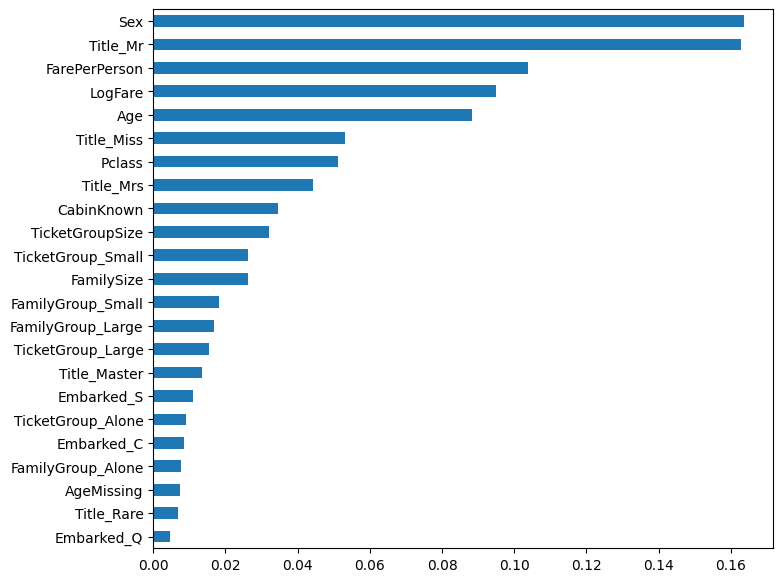

In [28]:
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=42).fit(X, y)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.plot(kind="barh", figsize=(8, 7)); plt.gca().invert_yaxis(); plt.show()

**Ablation**

In [29]:
def drop_and_eval(cols, label):
    cols = [c for c in X.columns if not any(c.startswith(p) for p in cols)]
    m, s = evaluate(RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=42), X[cols])
    print(f"without {label:15s}: {m:.4f}")

print(f"all features         : {results['RF'][0]:.4f}")
drop_and_eval(["Title"], "Title")
drop_and_eval(["Embarked"], "Embarked")
drop_and_eval(["FamilyGroup", "FamilySize"], "Family")
drop_and_eval(["TicketGroup", "TicketGroupSize"], "TicketGroup")
drop_and_eval(["CabinKnown", "AgeMissing"], "missing flags")

all features         : 0.8325
without Title          : 0.8316
without Embarked       : 0.8325
without Family         : 0.8346
without TicketGroup    : 0.8280
without missing flags  : 0.8352
